# Лабораторная работа № 12. Анализ многомерных данных с использованием методов снижения размерности
**Дисциплина:** Методы искусственного интеллекта  
**Студент:** Мальцев Николай Артемович  
**Группа:** ИНС-м-о-25-2

**Цель:** научиться применять обучаемые алгоритмы снижения размерности для визуализации наборов данных с большой размерностью.

**Задачи:** повторно использовать код; освоить обучаемые алгоритмы снижения размерности; обосновывать выбор методов и сравнивать карты многомерных данных.

## 1. Локальный запуск
Используем прежнее Conda-окружение `rcaeval-ai`. В VS Code выбираем его ядро и выполняем **Run All**. В `environment.yml` добавлен UMAP; Pillow явно указан для чтения изображений. При необходимости обновляем окружение из корня:
```bash
conda env update --prefix .conda/rcaeval-ai -f environment.yml
```

Повторный запуск читает сохранённые данные. RCAEval не скачивается заново. Таблицы, координаты, результаты и рисунки сохраняются в папке этой работы внутри `reports/`.

Подключаем библиотеки для файлов, таблиц и графиков.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from importlib.metadata import version
from time import perf_counter
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

Подключаем методы машинного обучения.

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import VarianceThreshold
from sklearn.decomposition import PCA, FastICA, TruncatedSVD
from sklearn.manifold import MDS, TSNE, trustworthiness
from sklearn.metrics import silhouette_score
from scipy.spatial.distance import pdist
import umap

import gzip
import zipfile
from PIL import Image

/home/nik/Desktop/AILabs/.conda/rcaeval-ai/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Задаём пути и настройки.

In [3]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'environment.yml').is_file() and (p / 'notebooks').is_dir())
REPORT = ROOT / 'reports/lab12'
FIGURES = REPORT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
SEED = 17
sns.set_theme(style='whitegrid')

Печатаем и сохраняем версии библиотек.

In [4]:
versions = {'Python': platform.python_version()}
versions.update({name: version(name) for name in ['numpy', 'pandas', 'matplotlib', 'scikit-learn', 'umap-learn', 'Pillow']})
display(pd.Series(versions, name='Версия'))
(REPORT / 'versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')

Python          3.11.17
numpy             2.2.6
pandas            2.3.3
matplotlib       3.10.9
scikit-learn      1.7.2
umap-learn       0.5.12
Pillow           12.3.0
Name: Версия, dtype: object

167

Определяем функцию сохранения и показа рисунков.

In [5]:
def save_show(fig, filename):
    fig.savefig(FIGURES / filename, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)

### 1.1. Методы и смысл карты
PCA сохраняет направления большого разброса; ICA ищет относительно независимые составляющие; TruncatedSVD строит компактное линейное представление. MDS старается сохранить общие расстояния, t-SNE и UMAP — соседство объектов.

Для сравнения используем одни и те же строки и входные признаки. Метки задают **только цвет**, в обучение карт не передаются. Координаты разных методов имеют разные шкалы; поворот или отражение карты сами по себе не меняют соседство.

Определяем шесть методов для карты из двух координат.

In [6]:
def reduction_methods():
    return {
        'PCA': PCA(n_components=2, random_state=SEED),
        'ICA': FastICA(n_components=2, max_iter=2000, tol=0.01, random_state=SEED),
        'TruncatedSVD': TruncatedSVD(n_components=2, random_state=SEED),
        'MDS': MDS(n_components=2, n_init=1, max_iter=300, normalized_stress=True, random_state=SEED),
        't-SNE': TSNE(n_components=2, perplexity=30, max_iter=1000, init='pca', learning_rate='auto', random_state=SEED),
        'UMAP': umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, n_epochs=300, random_state=SEED, n_jobs=1)
    }

Определяем показатели сохранения соседства и расстояний.

In [7]:
def embedding_quality(X, coordinates, labels):
    original_distance = pdist(X)
    map_distance = pdist(coordinates)
    scale = np.dot(original_distance, map_distance) / np.dot(map_distance, map_distance)
    stress = np.sqrt(np.sum((original_distance - scale * map_distance) ** 2)
                     / np.sum(original_distance ** 2))
    return {'trustworthiness': trustworthiness(X, coordinates, n_neighbors=10),
            'stress': float(stress), 'silhouette': silhouette_score(coordinates, labels)}

**Trustworthiness** от 0 до 1 оценивает сохранение локальных соседей, больше — лучше. **Stress** здесь — относительное искажение всех попарных расстояний после подбора одного общего масштаба карты, меньше — лучше. Одна формула применяется ко всем методам.

**Silhouette** от −1 до 1 показывает разделение заданных цветовых групп в новых координатах. Это описание карты с известными метками, а не точность классификатора. Методы могут выигрывать по разным критериям.

Определяем функцию расчёта и сохранения карт.

In [8]:
def compare_embeddings(X, labels, prefix):
    embeddings, rows = {}, []
    for name, method in reduction_methods().items():
        start = perf_counter()
        coordinates = method.fit_transform(X)
        elapsed = perf_counter() - start
        embeddings[name] = coordinates
        rows.append({'method': name, **embedding_quality(X, coordinates, labels), 'seconds': elapsed})
    table = pd.DataFrame(rows)
    table.to_csv(REPORT / f'{prefix}_metrics.csv', index=False)
    np.savez_compressed(REPORT / f'{prefix}_coordinates.npz', **embeddings)
    return embeddings, table

Определяем функцию показа шести карт с одинаковыми метками.

In [9]:
def show_embeddings(embeddings, labels, title, filename, hue_order=None):
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    for ax, (name, coordinates) in zip(axes.flat, embeddings.items()):
        sns.scatterplot(x=coordinates[:, 0], y=coordinates[:, 1], hue=labels,
                        palette='tab10', hue_order=hue_order, s=16, alpha=0.7, ax=ax)
        ax.set(title=name, xlabel='Координата 1', ylabel='Координата 2')
        ax.get_legend().remove()
    handles, legend_labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, legend_labels, title='Метка', loc='lower center', ncol=min(5, len(legend_labels)))
    fig.suptitle(title)
    fig.tight_layout(rect=(0, 0.1, 1, 0.96))
    save_show(fig, filename)

## 2. Учебная задача и пункт 1: Fashion-MNIST
### 2.1. Изображения и метки
Следуем примеру из ссылки на с. 117: читаем изображения 28×28, показываем одежду, превращаем пиксели в признаки и строим PCA. Затем выполняем обязательные ICA, TruncatedSVD, MDS, t-SNE и UMAP.

Полный набор имеет 60 000 обучающих и 10 000 тестовых изображений. Для учебного PCA выбираем 1000 обучающих изображений и 400 тестовых, поровну по десяти классам. Для сравнения шести карт берём одни и те же 400 обучающих изображений — по 40 каждого класса. Так MDS и сравнение расстояний выполняются за разумное время. Это выборка настоящих изображений, а не искусственные данные.

Скачиваем четыре файла Fashion-MNIST только при отсутствии локальных копий.

In [10]:
FASHION = ROOT / 'data/raw/fashion'
FASHION.mkdir(parents=True, exist_ok=True)
fashion_revision = 'b2617bb6d3ffa2e429640350f613e3291e10b141'
fashion_base = f'https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/{fashion_revision}/data/fashion/'
fashion_files = ['train-images-idx3-ubyte.gz', 'train-labels-idx1-ubyte.gz',
                 't10k-images-idx3-ubyte.gz', 't10k-labels-idx1-ubyte.gz']
for name in fashion_files:
    path = FASHION / name
    if not path.exists():
        path.write_bytes(urlopen(fashion_base + name, timeout=120).read())

Читаем изображения и метки из gzip без установки idx2numpy.

In [11]:
def read_fashion_images(path):
    with gzip.open(path, 'rb') as file:
        return np.frombuffer(file.read(), dtype=np.uint8, offset=16).reshape(-1, 28, 28)

def read_fashion_labels(path):
    with gzip.open(path, 'rb') as file:
        return np.frombuffer(file.read(), dtype=np.uint8, offset=8)

fashion_train = read_fashion_images(FASHION / fashion_files[0])
fashion_train_labels = read_fashion_labels(FASHION / fashion_files[1])
fashion_test = read_fashion_images(FASHION / fashion_files[2])
fashion_test_labels = read_fashion_labels(FASHION / fashion_files[3])

Показываем размеры массивов и названия классов.

In [12]:
fashion_names = {0: 'Футболка', 1: 'Брюки', 2: 'Пуловер', 3: 'Платье', 4: 'Пальто',
                 5: 'Сандалии', 6: 'Рубашка', 7: 'Кроссовки', 8: 'Сумка', 9: 'Ботинки'}
print('Обучение:', fashion_train.shape, '| Метки:', fashion_train_labels.shape)
print('Тест:', fashion_test.shape, '| Метки:', fashion_test_labels.shape)
display(pd.Series(fashion_names, name='Класс'))

Обучение: (60000, 28, 28) | Метки: (60000,)
Тест: (10000, 28, 28) | Метки: (10000,)


0     Футболка
1        Брюки
2      Пуловер
3       Платье
4       Пальто
5     Сандалии
6      Рубашка
7    Кроссовки
8        Сумка
9      Ботинки
Name: Класс, dtype: object

Показываем по одному настоящему изображению каждого класса.

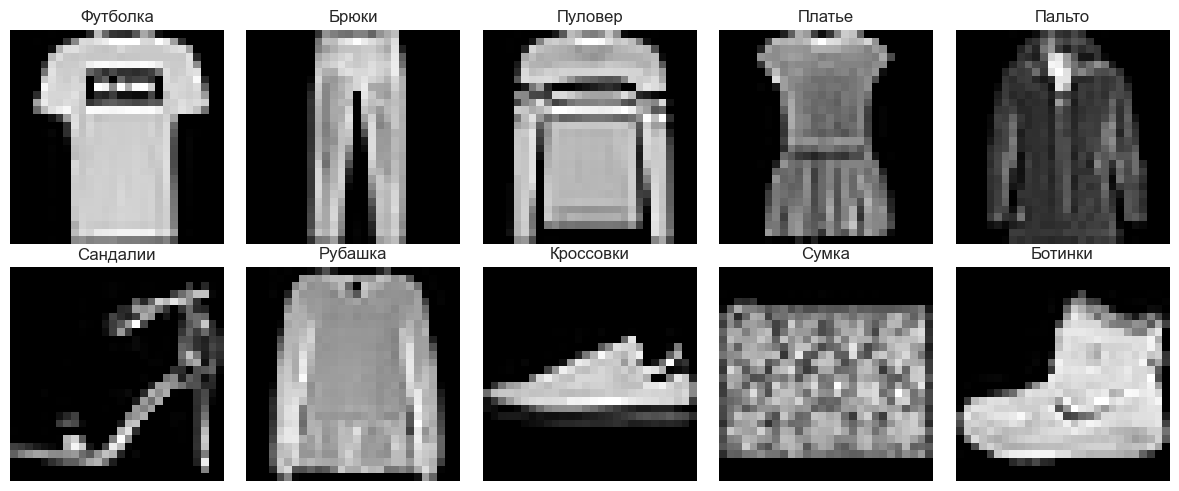

In [13]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for label, ax in enumerate(axes.flat):
    index = np.flatnonzero(fashion_train_labels == label)[0]
    ax.imshow(fashion_train[index], cmap='gray', vmin=0, vmax=255)
    ax.set_title(fashion_names[label])
    ax.axis('off')
fig.tight_layout()
save_show(fig, '01_fashion_examples.png')

Один снимок содержит 784 числовых пикселя. Метка обозначает вещь, но не передаётся алгоритму построения карты. Похожие силуэты, например рубашка и футболка, могут находиться рядом после снижения размерности.

Определяем фиксированный выбор одинакового числа изображений каждого класса.

In [14]:
def balanced_indices(labels, per_class):
    rng = np.random.default_rng(SEED)
    return np.sort(np.concatenate([rng.choice(np.flatnonzero(labels == label), per_class, replace=False)
                                   for label in np.unique(labels)]))

Выбираем изображения и превращаем пиксели в признаки 0–1.

In [15]:
train_sample_idx = balanced_indices(fashion_train_labels, 100)
test_sample_idx = balanced_indices(fashion_test_labels, 40)
map_sample_idx = balanced_indices(fashion_train_labels, 40)
F_train = fashion_train[train_sample_idx].reshape(-1, 784).astype(np.float32) / 255
F_test = fashion_test[test_sample_idx].reshape(-1, 784).astype(np.float32) / 255
F_maps = fashion_train[map_sample_idx].reshape(-1, 784).astype(np.float32) / 255
F_train_y = fashion_train_labels[train_sample_idx]
F_test_y = fashion_test_labels[test_sample_idx]
F_map_y = fashion_train_labels[map_sample_idx]
print('PCA обучение:', F_train.shape, '| PCA тест:', F_test.shape, '| Сравнение:', F_maps.shape)

PCA обучение: (1000, 784) | PCA тест: (400, 784) | Сравнение: (400, 784)


Деление на 255 одинаково для обеих частей и использует известный диапазон яркости. PCA сам вычисляет среднее обучения и центрирует данные. Тестовая часть преобразуется той же обученной PCA, без повторного подбора её осей.

Обучаем PCA по выбранным обучающим изображениям и преобразуем тестовые.

In [16]:
fashion_pca = PCA(n_components=2, random_state=SEED)
F_train_pca = fashion_pca.fit_transform(F_train)
F_test_pca = fashion_pca.transform(F_test)
print('Разброс, сохранённый двумя компонентами:', fashion_pca.explained_variance_ratio_.sum())

Разброс, сохранённый двумя компонентами: 0.4750554


Строим карты обучения и теста в одних координатах PCA.

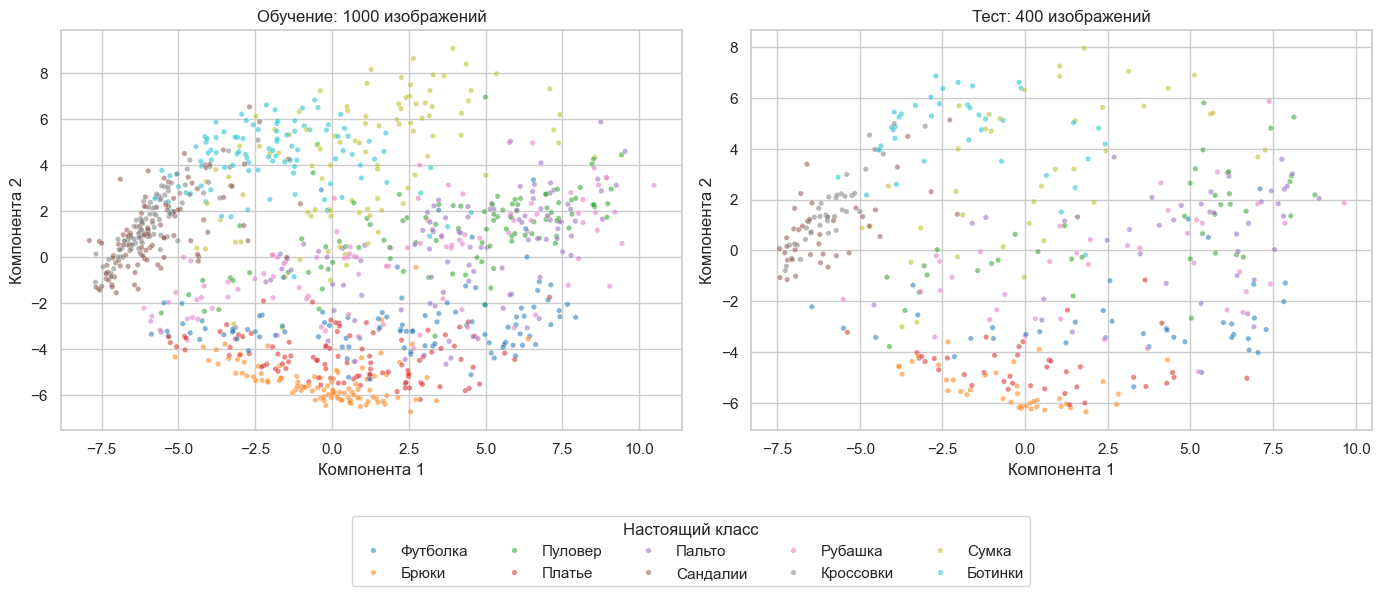

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, coordinates, labels, title in zip(axes, [F_train_pca, F_test_pca], [F_train_y, F_test_y], ['Обучение: 1000 изображений', 'Тест: 400 изображений']):
    names = np.array([fashion_names[int(label)] for label in labels])
    sns.scatterplot(x=coordinates[:, 0], y=coordinates[:, 1], hue=names, hue_order=list(fashion_names.values()),
                    palette='tab10', s=15, alpha=0.55, ax=ax)
    ax.set(title=title, xlabel='Компонента 1', ylabel='Компонента 2')
    ax.get_legend().remove()
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, title='Настоящий класс', loc='lower center', ncol=5)
fig.tight_layout(rect=(0, 0.16, 1, 1))
save_show(fig, '02_fashion_pca_train_test.png')

Оси обеих панелей относятся к одной PCA. Близкие точки похожи в этом представлении; перекрытие цветов показывает, что две компоненты не полностью разделяют вещи. Доля сохранённого разброса не равна точности распознавания одежды.

### 2.2. Шесть методов на одинаковых изображениях — пункт 1

Рассчитываем PCA и все пять методов индивидуального пункта 1.

In [18]:
fashion_maps, fashion_metrics = compare_embeddings(F_maps, F_map_y, 'fashion')
display(fashion_metrics.round(3))

,method,trustworthiness,stress,silhouette,seconds
0,PCA,0.928,0.271,-0.040,0.005
1,ICA,0.929,0.268,-0.032,0.030
2,TruncatedSVD,0.922,0.273,-0.049,0.005
3,MDS,0.927,0.249,-0.018,0.314
4,t-SNE,0.977,0.328,0.135,1.297
5,UMAP,0.975,0.402,0.105,7.300


Показываем шесть карт Fashion-MNIST.

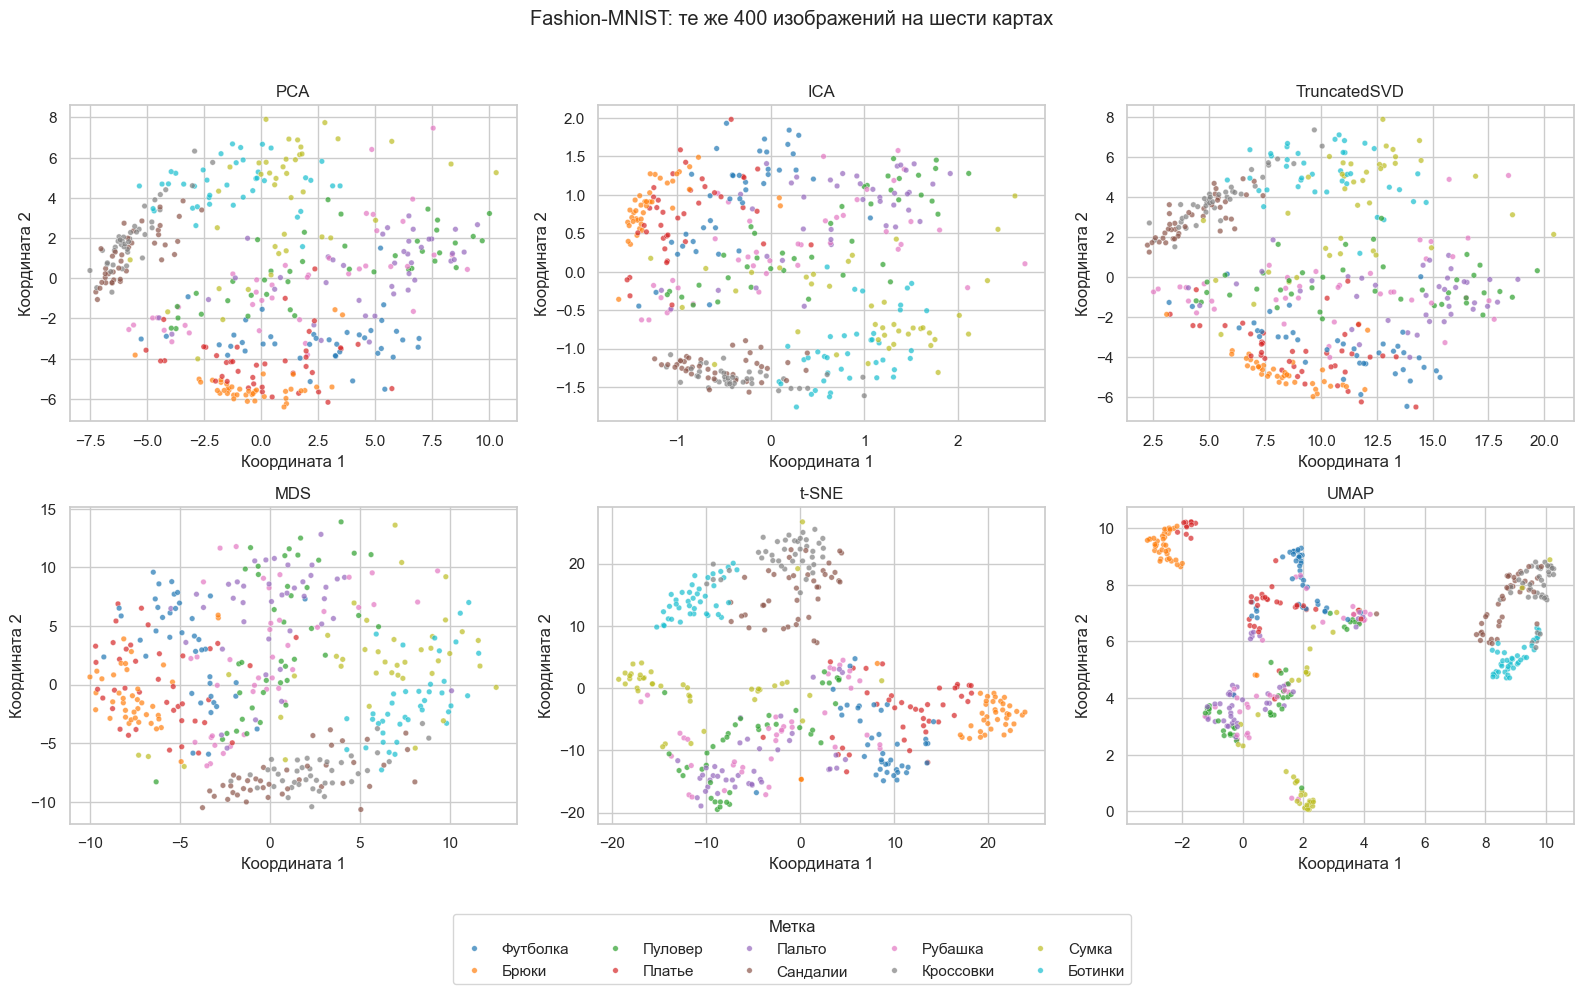

In [19]:
fashion_map_names = np.array([fashion_names[int(label)] for label in F_map_y])
show_embeddings(fashion_maps, fashion_map_names, 'Fashion-MNIST: те же 400 изображений на шести картах',
                '03_fashion_maps.png', hue_order=list(fashion_names.values()))

На всех панелях представлены те же изображения и цвета классов. PCA и ICA дают линейные комбинации яркости; t-SNE и UMAP часто лучше выделяют локальные группы. MDS ориентируется на общие расстояния. Большое расстояние между группами t-SNE не обязательно означает настолько же большое различие исходных вещей. Это исследование структуры, а не проверка классификатора.

## 3. Индивидуальное задание: визуальный мониторинг дефектов
### 3.1. Выбор KolektorSDD — пункт 2
Для этой работы табличный RCAEval не подходит: методичка требует набор **изображений**. Используем KolektorSDD лаборатории ViCoS — реальные снимки поверхностей промышленных изделий при контроле дефектов. Это задача визуального мониторинга качества, связанная с обнаружением неисправностей, хотя она не относится к Kubernetes.

Набор содержит 399 изображений: 52 с видимым дефектом и 347 без него. Для изображения имеется маска разметки. По ней определяем метку, но **не включаем маску в признаки**. Несколько снимков могут относиться к одному изделию; здесь изучаем карты всех изображений и не объявляем их независимой проверкой детектора.

Источник: [ViCoS — KolektorSDD](https://www2.vicos.si/resources/kolektorsdd/). Авторы: Domen Tabernik, Samo Šela, Jure Skvarč, Danijel Skočaj. Лицензия CC BY-NC-SA 4.0; статья *Segmentation-Based Deep-Learning Approach for Surface-Defect Detection*, 2019.

Получаем официальный архив только при отсутствии локальной копии и распаковываем его.

In [20]:
KOLEKTOR = ROOT / 'data/raw/kolektor'
KOLEKTOR.mkdir(parents=True, exist_ok=True)
archive_path = KOLEKTOR / 'KolektorSDD.zip'
image_root = KOLEKTOR / 'images'
kolektor_url = 'https://data.vicos.si/datasets/KSDD/KolektorSDD.zip'
if not archive_path.exists():
    archive_path.write_bytes(urlopen(kolektor_url, timeout=120).read())
if not image_root.exists():
    with zipfile.ZipFile(archive_path) as archive:
        archive.extractall(image_root)

Собираем изображения, их метки и пиксельные признаки.

In [21]:
image_paths = sorted(image_root.rglob('*.jpg'))
image_rows, image_vectors = [], []
for path in image_paths:
    image = Image.open(path).convert('L')
    mask = np.asarray(Image.open(path.with_name(path.stem + '_label.bmp')).convert('L'))
    resized = image.resize((64, 160), resample=Image.Resampling.BILINEAR)
    image_vectors.append(np.asarray(resized, dtype=np.float32).ravel() / 255)
    image_rows.append({'file': str(path.relative_to(image_root)), 'item': path.parent.name,
                       'width': image.width, 'height': image.height, 'defect': int(mask.max() > 0)})
image_info = pd.DataFrame(image_rows)
K = np.stack(image_vectors)
K_y = image_info.defect.to_numpy()

Показываем размеры, метки и число изделий.

In [22]:
display(image_info.head())
display(image_info.defect.value_counts().sort_index().rename(index={0: 'Без дефекта', 1: 'Дефект'}).rename('Изображений'))
print('Пиксельные признаки:', K.shape)
print('Изделий:', image_info.item.nunique())
print('Размеры оригиналов:', image_info[['width', 'height']].drop_duplicates().to_dict('records'))

,file,item,width,height,defect
0,kos01/Part0.jpg,kos01,500,1263,0
1,kos01/Part1.jpg,kos01,500,1261,0
2,kos01/Part2.jpg,kos01,500,1254,0
3,kos01/Part3.jpg,kos01,500,1260,0
4,kos01/Part4.jpg,kos01,500,1271,0


defect
Без дефекта    347
Дефект          52
Name: Изображений, dtype: int64

Пиксельные признаки: (399, 10240)
Изделий: 50
Размеры оригиналов: [{'width': 500, 'height': 1263}, {'width': 500, 'height': 1261}, {'width': 500, 'height': 1254}, {'width': 500, 'height': 1260}, {'width': 500, 'height': 1271}, {'width': 500, 'height': 1270}, {'width': 500, 'height': 1267}, {'width': 500, 'height': 1284}, {'width': 500, 'height': 1264}, {'width': 500, 'height': 1262}, {'width': 500, 'height': 1249}, {'width': 500, 'height': 1259}, {'width': 500, 'height': 1265}, {'width': 500, 'height': 1268}, {'width': 500, 'height': 1281}, {'width': 500, 'height': 1266}, {'width': 500, 'height': 1258}, {'width': 500, 'height': 1276}, {'width': 500, 'height': 1253}, {'width': 500, 'height': 1274}, {'width': 500, 'height': 1252}, {'width': 500, 'height': 1272}, {'width': 500, 'height': 1256}, {'width': 500, 'height': 1273}, {'width': 500, 'height': 1257}, {'width': 500, 'height': 1248}, {'width': 500, 'height': 1269}, {'width': 500, 'height': 1282}, {'width': 500, 'height': 1247}, {'wid

Для компактного расчёта снимки уменьшены до 64×160, примерно сохраняя пропорции, и представлены 10 240 яркостями от 0 до 1. Это подготовка настоящих изображений, не генерация новых наблюдений. Мелкие трещины при уменьшении могут стать слабее. Метки взяты из оригинальных масок. Во всех метриках сравнения исходным пространством считается именно эта подготовленная матрица, а не все пиксели полноразмерного снимка.

Показываем три оригинала с дефектом и три без дефекта.

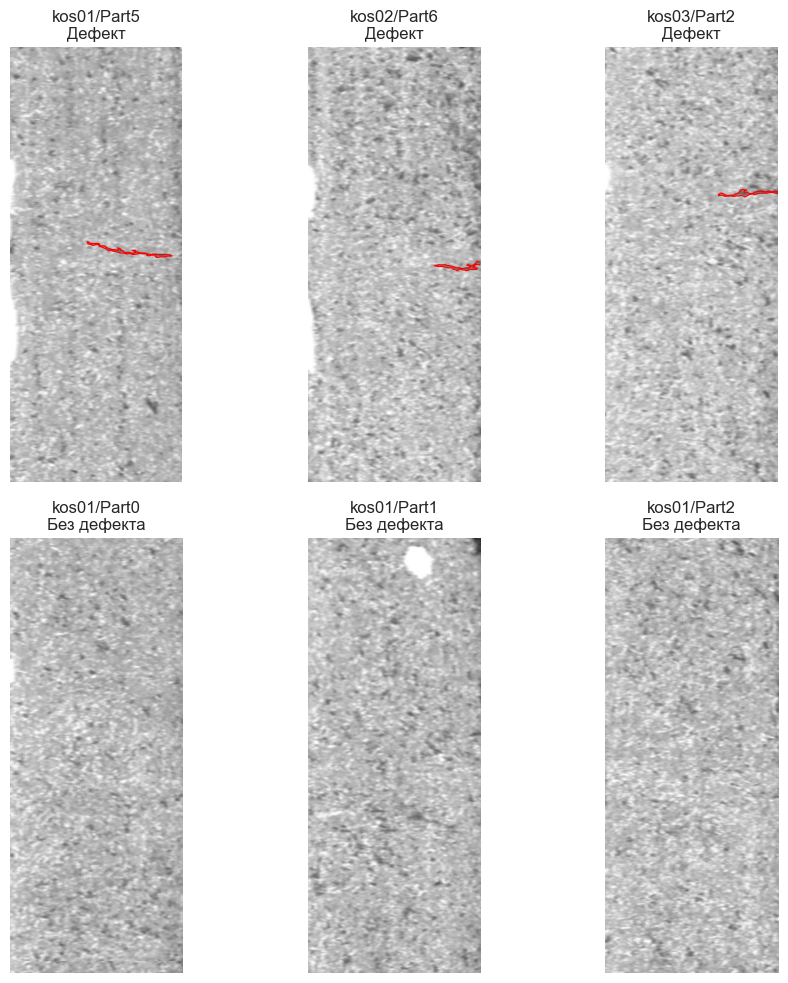

In [23]:
example_indices = np.r_[np.flatnonzero(K_y == 1)[:3], np.flatnonzero(K_y == 0)[:3]]
fig, axes = plt.subplots(2, 3, figsize=(10, 10))
for ax, index in zip(axes.flat, example_indices):
    path = image_paths[index]
    image = np.asarray(Image.open(path).convert('L'))
    ax.imshow(image, cmap='gray', vmin=0, vmax=255)
    if K_y[index] == 1:
        mask = np.asarray(Image.open(path.with_name(path.stem + '_label.bmp')).convert('L'))
        ax.contour(mask > 0, levels=[0.5], colors='red', linewidths=0.8)
    ax.set_title(f'{path.parent.name}/{path.stem}\n' + ('Дефект' if K_y[index] else 'Без дефекта'))
    ax.axis('off')
fig.tight_layout()
save_show(fig, '04_kolektor_examples.png')

Красный контур показывает разметку дефекта только для просмотра. Вход методов — яркость самого изображения; контур и маска туда не попадают. Дефекты могут занимать небольшую часть снимка, поэтому общая текстура и освещение иногда сильнее влияют на расстояние между пиксельными векторами.

### 3.2. Все методы снижения размерности — пункт 3

Рассчитываем шесть карт всех 399 изображений и их показатели.

In [24]:
kolektor_maps, kolektor_metrics = compare_embeddings(K, K_y, 'kolektor')
display(kolektor_metrics.round(3))

,method,trustworthiness,stress,silhouette,seconds
0,PCA,0.804,0.442,-0.058,0.068
1,ICA,0.799,0.393,-0.007,0.218
2,TruncatedSVD,0.796,0.446,-0.062,0.057
3,MDS,0.770,0.319,0.004,0.419
4,t-SNE,0.806,0.398,-0.009,1.699
5,UMAP,0.780,0.431,-0.015,0.586


Показываем карты промышленного набора с одинаковым цветом меток.

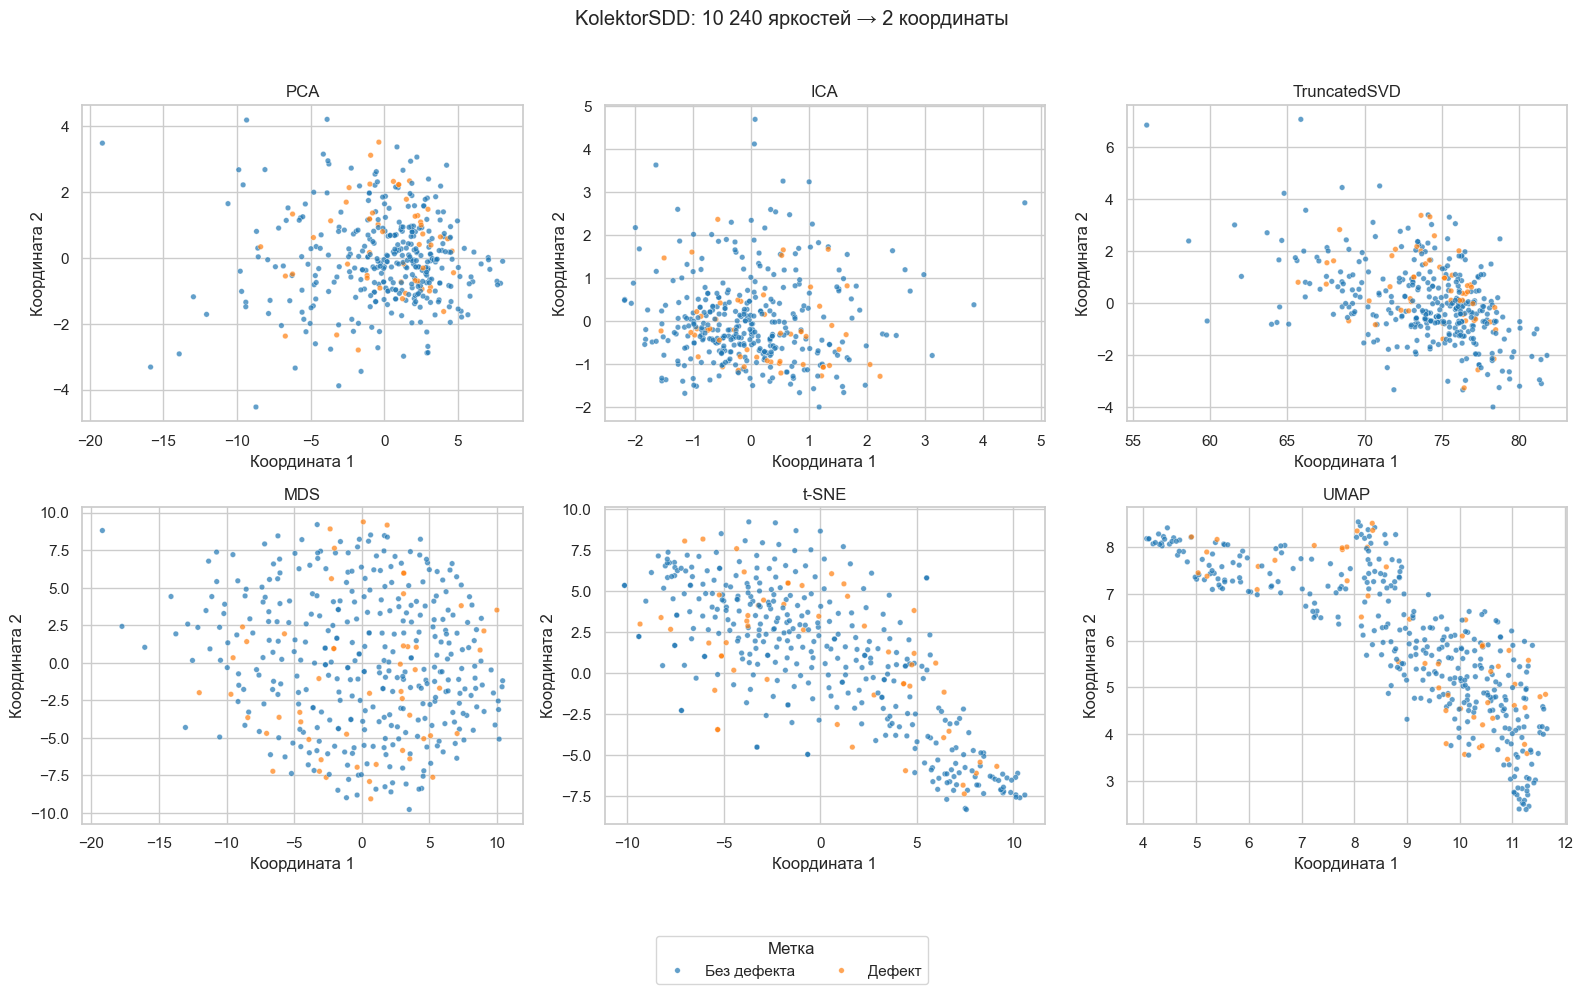

In [25]:
kolektor_names = np.where(K_y == 1, 'Дефект', 'Без дефекта')
show_embeddings(kolektor_maps, kolektor_names, 'KolektorSDD: 10 240 яркостей → 2 координаты',
                '05_kolektor_maps.png', hue_order=['Без дефекта', 'Дефект'])

Точка — реальный снимок поверхности; цвет взят из разметки после расчёта карты. Перемешивание цветов означает, что выбранное двухмерное представление не отделяет дефекты ясно. Отдельные группы могут отражать изделие, ракурс или освещение. По одному такому рисунку нельзя заявить, что построен точный детектор дефектов.

### 3.3. Сравнение качества и расстояний — пункт 4
Оцениваем каждый метод на той же матрице яркостей и тех же изображениях. Trustworthiness показывает локальное соседство; stress — общий рисунок расстояний; silhouette — разделение настоящих меток. Время зависит от компьютера и первого запуска: у UMAP оно может включать подготовительную компиляцию. Оно приведено как наблюдение этого запуска, а не универсальная скорость метода.

При выборе метода сначала определяем цель. Для просмотра похожих снимков полезна высокая trustworthiness. Для сохранения общих расстояний — низкий stress. Для будущего обнаружения дефектов нужны отдельная модель, разделение по изделиям и проверка её ошибок; silhouette этой проверки не заменяет.

Строим сравнение сохранения соседства и расстояний.

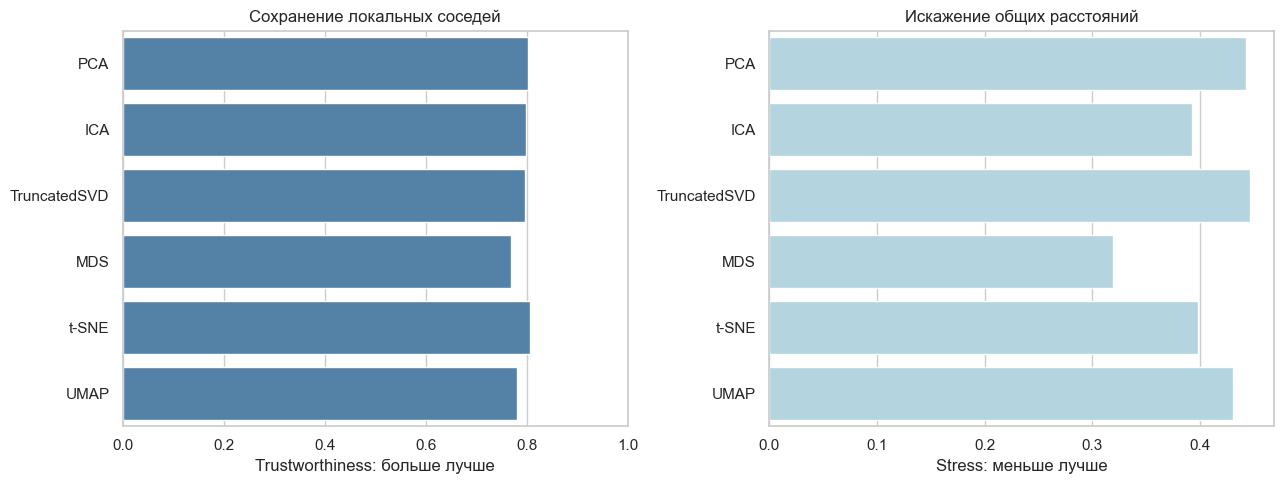

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=kolektor_metrics, x='trustworthiness', y='method', color='steelblue', ax=axes[0])
sns.barplot(data=kolektor_metrics, x='stress', y='method', color='lightblue', ax=axes[1])
axes[0].set(title='Сохранение локальных соседей', xlabel='Trustworthiness: больше лучше', ylabel='', xlim=(0, 1))
axes[1].set(title='Искажение общих расстояний', xlabel='Stress: меньше лучше', ylabel='')
fig.tight_layout()
save_show(fig, '06_kolektor_quality.png')

Левая панель показывает, какие карты лучше сохранили близких соседей в подготовленных пикселях. Правая — какие меньше исказили все расстояния. Один метод может хорошо сохранить ближайшие снимки и при этом плохо передать расстояния между далёкими группами.

Сравниваем расстояния одних и тех же пар изображений.

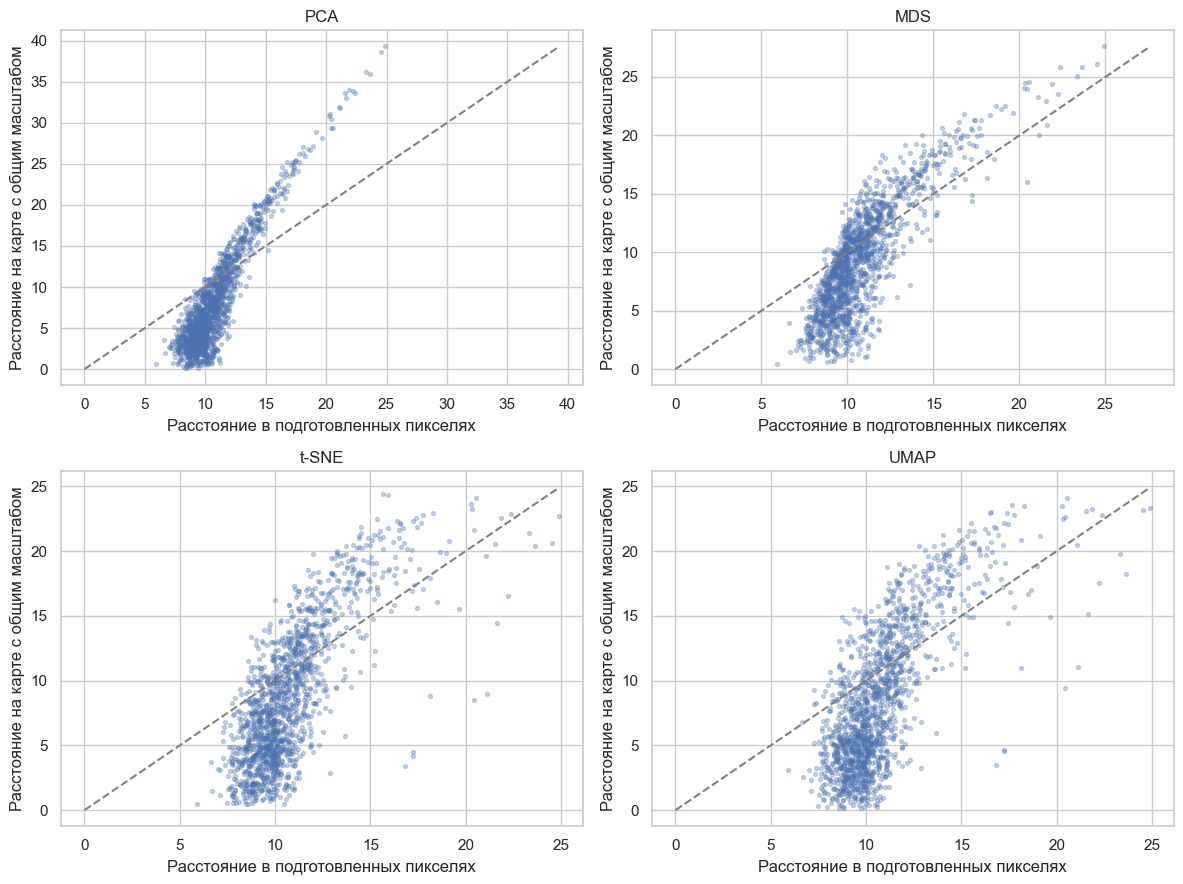

In [27]:
original_distance = pdist(K)
rng = np.random.default_rng(SEED)
pair_indices = rng.choice(len(original_distance), 1500, replace=False)
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, name in zip(axes.flat, ['PCA', 'MDS', 't-SNE', 'UMAP']):
    map_distance = pdist(kolektor_maps[name])
    scale = np.dot(original_distance, map_distance) / np.dot(map_distance, map_distance)
    ax.scatter(original_distance[pair_indices], scale * map_distance[pair_indices], s=8, alpha=0.3)
    maximum = max(original_distance[pair_indices].max(), (scale * map_distance[pair_indices]).max())
    ax.plot([0, maximum], [0, maximum], '--', color='gray')
    ax.set(title=name, xlabel='Расстояние в подготовленных пикселях', ylabel='Расстояние на карте с общим масштабом')
fig.tight_layout()
save_show(fig, '07_kolektor_distances.png')

Точка теперь означает пару снимков, а не один снимок. На пунктире расстояние сохранилось после одного общего изменения масштаба карты. Широкий разброс показывает искажение расстояний. У t-SNE и UMAP такое искажение дальних пар может сочетаться с хорошим локальным соседством.

Проверяем чувствительность t-SNE к другому seed на тех же снимках.

In [28]:
second_tsne = TSNE(n_components=2, perplexity=30, max_iter=1000, init='pca', learning_rate='auto',
                   random_state=SEED + 1).fit_transform(K)
second_quality = embedding_quality(K, second_tsne, K_y)
display(pd.DataFrame([
    {'seed': SEED, **embedding_quality(K, kolektor_maps['t-SNE'], K_y)},
    {'seed': SEED + 1, **second_quality}
]))

,seed,trustworthiness,stress,silhouette
0,17,0.806203,0.398328,-0.009187
1,18,0.808496,0.392807,-0.002693


Два запуска помогают увидеть, зависят ли показатели t-SNE от начального состояния. Даже близкие оценки не гарантируют одинаковых координат. Окончательное сравнение методов относится к этим параметрам, уменьшенным снимкам и данному набору.

Формируем вывод по рассчитанным показателям и сохраняем сведения о данных.

In [29]:
best_local = kolektor_metrics.loc[kolektor_metrics.trustworthiness.idxmax(), 'method']
best_global = kolektor_metrics.loc[kolektor_metrics.stress.idxmin(), 'method']
best_labels = kolektor_metrics.loc[kolektor_metrics.silhouette.idxmax(), 'method']
analysis = (f'Применил PCA, ICA, TruncatedSVD, MDS, t-SNE и UMAP к Fashion-MNIST и KolektorSDD. '
            f'Для промышленного набора обработано {len(K)} настоящих снимков, из них {int(K_y.sum())} с дефектом. '
            f'По сохранению локальных соседей лучший результат в этом опыте дал {best_local}, '
            f'по общим расстояниям — {best_global}, по silhouette меток — {best_labels}. '
            'Это разные цели: единственного лучшего метода для всех задач из таблицы не следует. '
            'Построенные карты помогают рассматривать похожие снимки, но не заменяют проверку детектора на других изделиях.')
display(Markdown(analysis))
(REPORT / 'analysis.md').write_text(analysis, encoding='utf-8')
image_info.to_csv(REPORT / 'kolektor_images.csv', index=False)
np.savez_compressed(REPORT / 'sample_indices.npz', train=train_sample_idx, test=test_sample_idx, comparison=map_sample_idx)
summary = {'fashion_total_train': len(fashion_train), 'fashion_total_test': len(fashion_test),
           'fashion_comparison_rows': len(F_maps), 'kolektor_rows': len(K), 'kolektor_defects': int(K_y.sum()),
           'image_size': [64, 160], 'features': K.shape[1], 'best_local': best_local, 'best_global': best_global,
           'best_silhouette': best_labels, 'metrics': kolektor_metrics.drop(columns='seconds').to_dict('records'),
           'figures': sorted(p.name for p in FIGURES.glob('*.png'))}
source_files = [FASHION / name for name in fashion_files] + [archive_path]
sources = {'fashion_base': fashion_base, 'kolektor_url': kolektor_url,
           'sha256': {str(p.relative_to(ROOT)): hashlib.sha256(p.read_bytes()).hexdigest() for p in source_files}}
(REPORT / 'results.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
(REPORT / 'sources.json').write_text(json.dumps(sources, ensure_ascii=False, indent=2), encoding='utf-8')

Применил PCA, ICA, TruncatedSVD, MDS, t-SNE и UMAP к Fashion-MNIST и KolektorSDD. Для промышленного набора обработано 399 настоящих снимков, из них 52 с дефектом. По сохранению локальных соседей лучший результат в этом опыте дал t-SNE, по общим расстояниям — MDS, по silhouette меток — MDS. Это разные цели: единственного лучшего метода для всех задач из таблицы не следует. Построенные карты помогают рассматривать похожие снимки, но не заменяют проверку детектора на других изделиях.

816

## 4. Заключение
Научился применять обучаемые алгоритмы снижения размерности для визуализации наборов данных с большой размерностью. Освоил превращение изображений в пиксельные признаки и построение карт PCA, ICA, TruncatedSVD, MDS, t-SNE и UMAP.

Выполнил пример Fashion-MNIST и индивидуальную работу на реальных снимках промышленного контроля KolektorSDD. Сравнил сохранение соседей, общих расстояний и разделение известных меток. Увидел, что наглядная карта не равна точному детектору и что выбор метода зависит от цели просмотра.

## 5. Ответы на контрольные вопросы
**1. Что такое проклятие размерности?**  
Когда признаков много, для надёжного описания данных нужно больше наблюдений. Расстояния становятся менее различимыми, расчёты усложняются, а модель легче запоминает случайные особенности. Снижение размерности уменьшает число признаков, а не обязательно число строк.

**2. Какие основные методы используются?**  
Отбор признаков: VarianceThreshold и статистический отбор. Создание новых признаков: PCA, ICA, TruncatedSVD, факторный анализ и LDA. Для нелинейных карт применяются MDS, Isomap, LLE, t-SNE и UMAP. Не все методы умеют затем преобразовать новые объекты без нового обучения.

**3. Как работает PCA?**  
После подготовки и центрирования данных находит направления с наибольшим разбросом. Затем берёт несколько таких направлений и проецирует на них объекты. Компоненты не коррелируют на обучающих данных, но это не гарантирует их статистической независимости. Доля сохранённого разброса показывает, сколько вариации осталось, а не accuracy модели.

**4. Какова идея t-SNE?**  
Метод старается сохранить близкое соседство объектов при переносе на плоскость. Он сравнивает вероятности соседства в исходных признаках и в новых координатах. На рисунке полезнее рассматривать локальных соседей, чем расстояния между далёкими группами. Размеры групп и их взаимное расположение могут меняться при других параметрах или seed.

**5. Существует ли предел снижения размерности?**  
Да, сохранить всю структуру в произвольно малом числе координат обычно нельзя. Предел без потерь связан с тем, сколько независимых направлений есть в данных. Две координаты удобны для просмотра, но могут потерять важные детали, например небольшую трещину. Подходящую размерность выбирают по сохранённым свойствам и результату конкретной задачи, а не только по красоте рисунка.